In [7]:
import sys
from pathlib import Path

root = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(root / "src"))
print("project root:", root)

project root: e:\Projects\biomed-ml


In [8]:
import numpy as np
import matplotlib.pyplot as plt
from biomed.datasets import BonnEEGDataset

X, y, groups = BonnEEGDataset().load()
print(X.shape, y.shape)
print(np.unique(y, return_counts=True))
print("recordings:", len(set(groups)))


(11500, 178) (11500,)
(array([1, 2, 3, 4, 5]), array([2300, 2300, 2300, 2300, 2300]))
recordings: 500


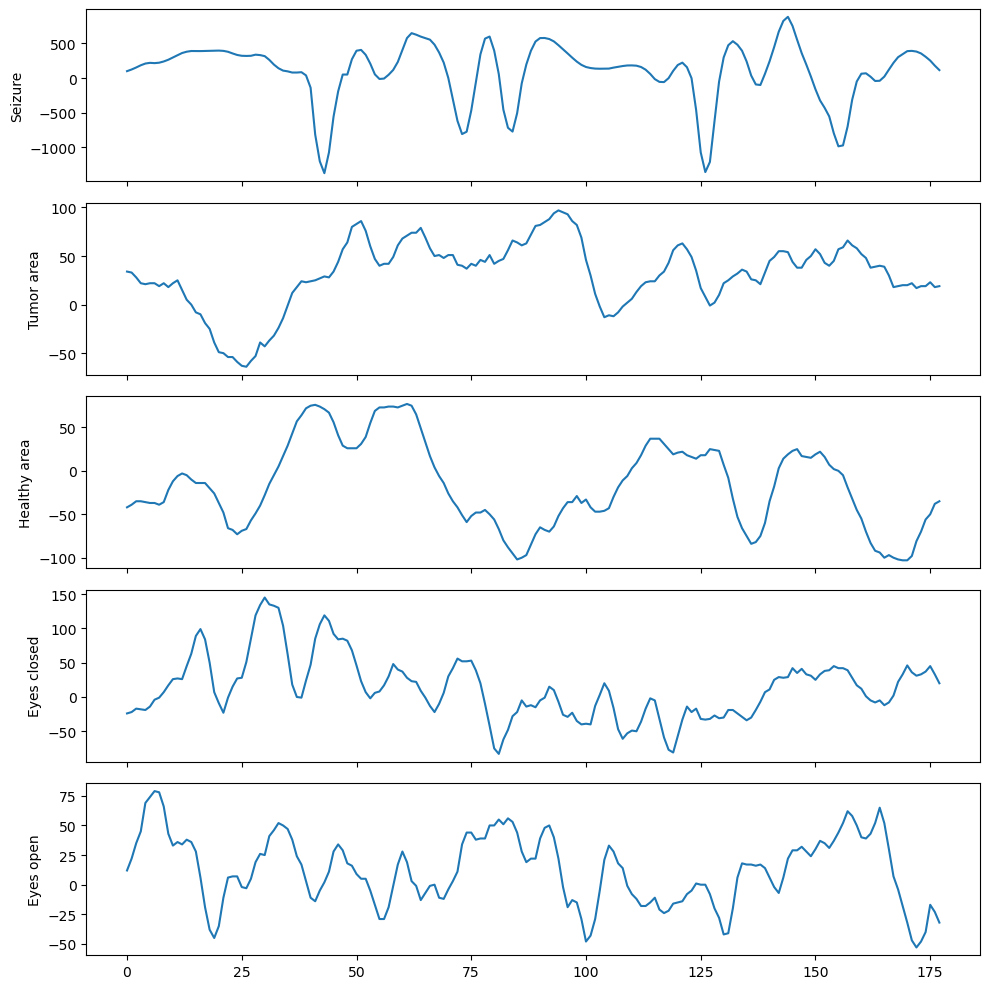

In [9]:
labels = {1: "Seizure", 2: "Tumor area", 3: "Healthy area",
          4: "Eyes closed", 5: "Eyes open"}

fig, axes = plt.subplots(5, 1, figsize=(10, 10), sharex=True)
for ax, (cls, name) in zip(axes, labels.items()):
    ax.plot(X[y == cls][0])
    ax.set_ylabel(name)
plt.tight_layout()
plt.show()


In [10]:
target = (y == 1).astype(int)
print(np.bincount(target))
print("seizure fraction:", target.mean())


[9200 2300]
seizure fraction: 0.2
